# Estado del arte: lo que midió la literatura y lo que omiten las herramientas

**Pregunta:** ¿Qué concluyeron los estudios publicados sobre el tamaño y la potencia de estas pruebas, y llega el motor, corrido hoy, a los mismos veredictos?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 02 a 06 de este tema (las mediciones con que se compara la literatura)
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- exponer lo que concluyeron el documento de trabajo 14 de BCBS, Yurdakul y Naranjo (2020) y Demler, Pencina y D'Agostino (2012) sobre el tamaño y la potencia de las pruebas de validación;
- recalcular, con el motor, los valores críticos que el documento de trabajo imprimió para la prueba binomial y el tamaño verdadero que implican con incumplimientos correlacionados;
- repetir celdas del estudio del PSI y del estudio de DeLong anidado con semillas nuevas y juzgarlas frente a las tasas publicadas;
- decidir, veredicto por veredicto, si una afirmación de la literatura se cumple, se cumple con una salvedad o no se cumple en el motor;
- decir qué documentan las herramientas de validación y qué dejan sin medir.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son los artefactos versionados del caso C22, validar al validador, sorteados con generadores de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`). Tres de ellos guardan, en `outputs.golden`, un estudio de simulación publicado: la tasa impresa en el artículo para cada celda, citada de él. La literatura misma se cita desde los expedientes de investigación del producto, que leyeron cada artículo en octubre de 2026; las citas textuales son literales de esas lecturas.

- **Archivos que se leen:** `data/derived/C22/clustering.json` (documento de trabajo 14 de BCBS, tablas 7 y 8, 144 celdas), `drift.json` (Yurdakul y Naranjo, tabla 4, 54 celdas), `leakage.json` (Demler et al., una celda) y `null.json`.
- **Qué se toma de ellos:** las tasas publicadas, y la configuración y la semilla de las filas que el motor corre de nuevo aquí.

La celda siguiente carga los cuatro artefactos e imprime las versiones del motor.

In [2]:
# Cargar los cuatro artefactos de la comparación e imprimir la versión del motor que calculó cada uno
LANG = "es"
ROOT = Path("../../..").resolve()
files = ("clustering", "drift", "leakage", "null")
artifacts = {}
for n in files:
    path = ROOT / "data" / "derived" / "C22" / f"{n}.json"
    artifacts[n] = json.loads(path.read_text(encoding="utf-8"))
rows = {n: {row["key"]: row for row in art["outputs"]["simulations"]} for n, art in artifacts.items()}
clustering, drift, leakage, null = (artifacts[n] for n in files)
for n in files:
    print(f"{n:11s} calculado con riskvalidation {artifacts[n]['provenance']['riskvalidation_version']}")
print("instalado:", rv.__version__)

clustering  calculado con riskvalidation 1.0.1
drift       calculado con riskvalidation 1.0.1
leakage     calculado con riskvalidation 1.0.1
null        calculado con riskvalidation 1.0.1
instalado: 1.0.1


## Método

Una repetición de un estudio publicado se compara con el artículo celda por celda. La tasa del artículo $r_\text{pub}$ viene de $n_\text{pub}$ corridas y la nuestra, $\hat r$, de $n$ corridas; ambas estiman una misma tasa verdadera, así que su diferencia tiene varianza $\bar r(1-\bar r)(1/n + 1/n_\text{pub})$ con la tasa agrupada $\bar r$, y una celda concuerda cuando la diferencia estandarizada cumple $|z| \le 3{,}29$. El `agrees_with_published` del motor la calcula. Para cada veredicto que la literatura da sobre una prueba, el cuaderno corre luego el motor sobre esa prueba y dice si el veredicto se cumple, se cumple con una salvedad o no se cumple.

## Estado del arte

### Documento de trabajo 14 de BCBS (2005): las pruebas de calibración

El documento de trabajo 14 del Comité de Basilea (Studies on the validation of internal rating systems, revisado, mayo de 2005) evalúa las pruebas de calibración y corre un estudio de simulación de dos de ellas. Sus veredictos (páginas 41 y 42, traducidos del inglés):

- **Prueba binomial:** «Ejemplos del apéndice muestran que el error de tipo I verdadero (es decir, la probabilidad de rechazar erróneamente la hipótesis de un pronóstico de PD adecuado) puede ser mucho mayor que el nivel nominal de la prueba si los eventos de incumplimiento están correlacionados». Tomar en cuenta la dependencia «rinde pruebas de potencia bastante moderada, incluso con niveles bajos de correlación».
- **Prueba normal:** «Los estudios de simulación muestran que la calidad de la aproximación normal es moderada pero exhibe un sesgo conservador. En consecuencia, el error de tipo I verdadero tiende a ser menor que el nivel nominal de la prueba».
- **Conclusión:** «en la actualidad no hay pruebas realmente potentes de calibración adecuada. Por los efectos de correlación que deben respetarse, incluso parece no haber manera de desarrollar tales pruebas».

El apéndice imprime valores críticos de la prueba binomial para una PD de 1%, 1.000 deudores y una confianza de 99% (Ejemplo 3): 19 incumplimientos cuando los incumplimientos son independientes, y 35, 49, 63 y 77 cuando la correlación de activos es 5%, 10%, 15% y 20% (dossier 12, sección 2.2). La primera verificación los recalcula con el motor y calcula el tamaño verdadero que implican.

### Paso 1: la prueba binomial bajo correlación

`critical_count` halla el menor conteo de incumplimientos con que una prueba registrada rechaza. Con `pd.binomial` al nivel de 1 % entrega el valor crítico independiente, y con `pd.binomial_vasicek` con una correlación supuesta entrega el corregido. `rejection_probability` devuelve luego el tamaño verdadero de la prueba independiente cuando los incumplimientos siguen esa correlación. La celda siguiente imprime ambos conteos críticos y el tamaño verdadero para las correlaciones del documento, y dibuja el tamaño sobre una malla.

columnas: correlación de activos, k* corregido, k* independiente, tamaño verdadero
0.00   19   19 0.0069
0.05   35   19 0.1113
0.10   49   19 0.1441
0.15   63   19 0.1539
0.20   77   19 0.1549


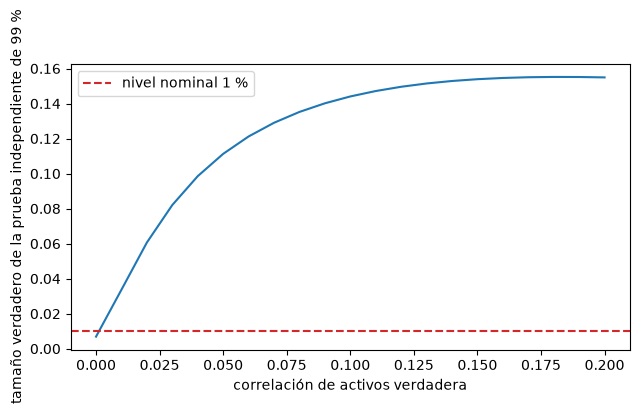

In [3]:
# Conteos críticos de la prueba binomial independiente y corregida y tamaño verdadero de la independiente
from riskvalidation.harness.exact import critical_count, rejection_probability

independent_k = critical_count("pd.binomial", 1000, 0.01, 0.01)
print("columnas: correlación de activos, k* corregido, k* independiente, tamaño verdadero")
size0 = rejection_probability("pd.binomial", 1000, 0.01, 0.01)["probability"]
print(f"{0.0:.2f} {independent_k:4d} {independent_k:4d} {size0:.4f}")
for rho in (0.05, 0.10, 0.15, 0.20):
    corrected_k = critical_count("pd.binomial_vasicek", 1000, 0.01, 0.01, rho=rho)
    size = rejection_probability("pd.binomial", 1000, 0.01, 0.01, rho_true=rho)["probability"]
    print(f"{rho:.2f} {corrected_k:4d} {independent_k:4d} {size:.4f}")
grid = np.linspace(0.0, 0.2, 21)
curve = [rejection_probability("pd.binomial", 1000, 0.01, 0.01, rho_true=r)["probability"] for r in grid]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(grid, curve)
ax.axhline(0.01, color="tab:red", linestyle="--", label="nivel nominal 1 %")
ax.set_xlabel("correlación de activos verdadera")
ax.set_ylabel("tamaño verdadero de la prueba independiente de 99 %")
ax.legend()
fig.tight_layout()
plt.show()

El motor devuelve los valores críticos del ejemplo del documento: 19 incumplimientos con incumplimientos independientes y 35, 49, 63 y 77 con correlaciones de activos de 5 %, 10 %, 15 % y 20 %. La prueba independiente, con su umbral de 19, tiene un tamaño verdadero de 0,0069 cuando los incumplimientos son independientes y 0,1113 con 5 %, 0,1441 con 10 %, 0,1539 con 15 % y 0,1549 con 20 %, frente a un 1 % nominal. El veredicto del documento de trabajo sobre la prueba binomial, que su error tipo I verdadero puede ser mucho mayor que el nominal bajo correlación, se cumple de forma exacta: el tamaño es más de diez veces el nivel.

### Paso 2: el veredicto sobre la prueba normal

El documento dice que la prueba normal «exhibits a conservative bias», con un error tipo I verdadero que «tends to be lower than the nominal level». Su propia tabla 7 informa el error tipo I al 5 % en ocho escenarios, cuatro con años independientes (`I_`) y cuatro con dependencia (`DC_`, `DV_`). La celda siguiente lee esas tasas publicadas y cuenta cuántas superan 5 % en cada grupo, y luego simula la prueba normal a lo largo de la escalera de agrupamiento con el motor, 1.000 repeticiones por peldaño, y dibuja las tasas publicadas junto a los tamaños medidos.

años independientes    tasas publicadas al 5 %: [0.059, 0.059, 0.077, 0.081]
                       sobre 5 %: 4 de 4
años dependientes      tasas publicadas al 5 %: [0.037, 0.049, 0.062, 0.07]
                       sobre 5 %: 2 de 4
tamaño de la prueba normal a lo largo de la escalera: [0.083, 0.091, 0.077, 0.056, 0.034, 0.039]


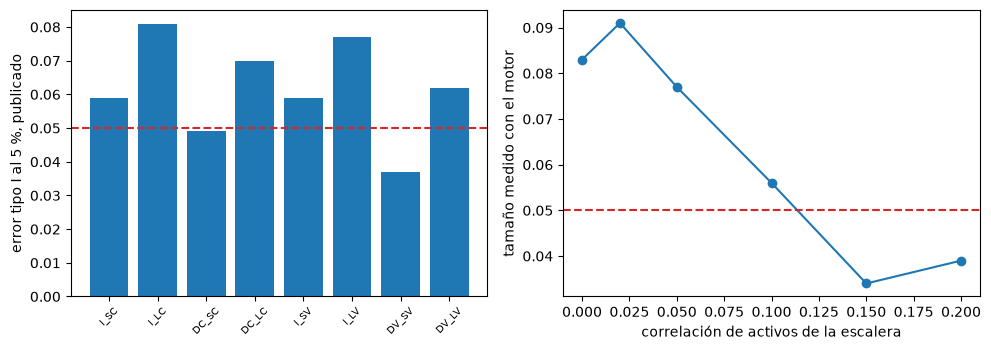

In [4]:
# Leer los errores tipo I publicados de la prueba normal y medir su tamaño a lo largo de la escalera de agrupamiento
from riskvalidation.generators.counts import DefaultCounts, feed_series
from riskvalidation.harness.run import simulate

study = clustering["outputs"]["golden"][0]
published = {c["row"]: c["published"] for c in study["cells"] if c["table"] == "Table 7" and c["column"] == "0.05"}
normal = {name: rate for name, rate in published.items() if "normal" in name}
for group, prefix in (("años independientes", "I_"), ("años dependientes", "D")):
    chosen = [rate for name, rate in normal.items() if name.startswith(prefix)]
    print(f"{group:22s} tasas publicadas al 5 %: {sorted(chosen)}")
    print(f"{'':22s} sobre 5 %: {sum(r > 0.05 for r in chosen)} de {len(chosen)}")
ladder = clustering["outputs"]["ladder"]["values"]
measured = []
for rho in ladder:
    row = rows["clustering"][f"pd.normal_multiperiod@rho{rho:g}"]
    generator = DefaultCounts(**clustering["outputs"]["generators"][row["generator"]]["config"])
    run = simulate(row["test_id"], generator, n_rep=1000, seed=row["seed"], feed=feed_series())
    measured.append(run.rates["p<0.05"].rate)
print("tamaño de la prueba normal a lo largo de la escalera:", [round(m, 4) for m in measured])
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(range(len(normal)), list(normal.values()), color="tab:blue")
left.axhline(0.05, color="tab:red", linestyle="--")
left.set_xticks(range(len(normal)))
left.set_xticklabels([name.split(",")[0] for name in normal], rotation=45, fontsize=7)
left.set_ylabel("error tipo I al 5 %, publicado")
right.plot(ladder, measured, "o-")
right.axhline(0.05, color="tab:red", linestyle="--")
right.set_xlabel("correlación de activos de la escalera")
right.set_ylabel("tamaño medido con el motor")
fig.tight_layout()
plt.show()

El veredicto se cumple solo con una salvedad. Con años independientes las cuatro tasas publicadas están sobre 5 %, entre 0,059 y 0,081, así que la prueba no es conservadora allí; con años dependientes dos de las cuatro están sobre él, entre 0,037 y 0,070. Los tamaños propios del motor a lo largo de la escalera van de 0,083 con incumplimientos independientes hasta 0,034 con una correlación de activos de 15 % y 0,039 con 20 %: la prueba rechaza de más cuando los años son independientes y de menos cuando son muy dependientes, y la palabra conservadora del documento describe solo el segundo caso.

### Paso 3: «no hay pruebas realmente potentes»

El documento concluye que no existe una prueba de calibración realmente potente con incumplimientos correlacionados. La prueba binomial corregida por Vasicek es su propia respuesta a la correlación, y su potencia exacta se calcula cuando la correlación verdadera iguala a la supuesta. La celda siguiente calcula la potencia al 5 % para 1.000 deudores con una PD de 1 % cuando la PD verdadera sube a 1,25; 1,5; 2 y 3 veces la PD aplicada, con correlaciones de activos de 5 % y 12 %, e imprime la prueba sin corregir junto a ella. En $k = 1$ la cifra es el tamaño, que dice si la potencia se compra con falsas alarmas.

correlación de activos 0.05 | corregida: [0.043, 0.087, 0.145, 0.284, 0.561]
correlación de activos 0.05 | sin corregir: [0.178, 0.282, 0.388, 0.576, 0.816]
correlación de activos 0.12 | corregida: [0.05, 0.08, 0.114, 0.19, 0.349]
correlación de activos 0.12 | sin corregir: [0.198, 0.27, 0.34, 0.465, 0.653]


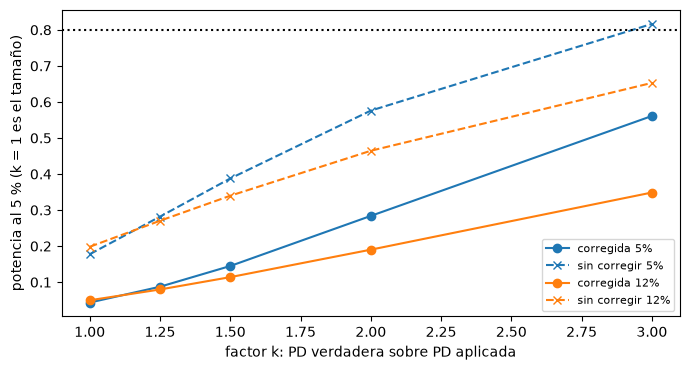

In [5]:
# Potencia exacta de la prueba binomial corregida y sin corregir con incumplimientos correlacionados, n = 1000, PD = 1 %
factors = np.array([1.0, 1.25, 1.5, 2.0, 3.0])
fig, ax = plt.subplots(figsize=(7, 3.8))
for index, rho in enumerate((0.05, 0.12)):
    corrected, plain = [], []
    for k in factors:
        kw = {"pd_true": 0.01 * k, "rho_true": rho}
        corrected.append(rejection_probability("pd.binomial_vasicek", 1000, 0.01, 0.05, rho=rho, **kw)["probability"])
        plain.append(rejection_probability("pd.binomial", 1000, 0.01, 0.05, **kw)["probability"])
    print(f"correlación de activos {rho:.2f} | corregida:", [round(p, 3) for p in corrected])
    print(f"correlación de activos {rho:.2f} | sin corregir:", [round(p, 3) for p in plain])
    ax.plot(factors, corrected, "o-", color=f"C{index}", label=f"corregida {rho:.0%}")
    ax.plot(factors, plain, "x--", color=f"C{index}", label=f"sin corregir {rho:.0%}")
ax.axhline(0.8, color="black", linestyle=":")
ax.set_xlabel("factor k: PD verdadera sobre PD aplicada")
ax.set_ylabel("potencia al 5 % (k = 1 es el tamaño)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Con una correlación de activos de 5 % la prueba corregida tiene un tamaño de 0,043 y su potencia es 0,087; 0,145; 0,284 y 0,561 para $k$ = 1,25; 1,5; 2 y 3; con 12 % es 0,050 en $k = 1$ y 0,349 en $k = 3$. Son cifras modestas: una PD tres veces demasiado baja pasa inadvertida una vez de cada dos con 5 % y dos veces de cada tres con 12 %. La prueba sin corregir es mucho más potente, 0,816 y 0,653 en $k = 3$, pero en $k = 1$ rechaza 0,178 y 0,198 de los modelos correctos. El veredicto se cumple con una salvedad: las pruebas con tamaño honesto son débiles, y las potentes no son honestas.

### Yurdakul y Naranjo (2020): el PSI

Yurdakul y Naranjo (Statistical properties of the population stability index, Journal of Risk Model Validation 14(4)) parten de la observación de que las bandas del PSI de 0,10 y 0,25 se «usan sin referencia a tasas de error estadístico de tipo I o de tipo II». Derivan la distribución muestral del índice (su Teorema 3.3), proponen la referencia $(1/n + 1/m)\,\chi^2_{1-\alpha,\,B-1}$ e informan una simulación (Tabla 4) con 10.000 corridas. Su lectura (traducida del inglés): «la tasa de error de tipo I para PSI > 0,10 es demasiado grande, salvo cuando ambos tamaños de muestra superan 400. En cambio, la tasa de error de tipo I para PSI > 0,25 es demasiado pequeña cuando ambos tamaños de muestra superan 200, de modo que la prueba es demasiado conservadora. La referencia chi-cuadrado mantiene un error de tipo I razonable, cercano a $\alpha$ = 0,05 [...] las pruebas PSI > 0,10 y PSI > 0,25 tienen potencias que en realidad disminuyen con el tamaño de muestra».


### Paso 4: el estudio del PSI, repetido

Yurdakul y Naranjo corrieron 10.000 corridas por celda de su tabla 4. La celda siguiente repite las celdas de muestras iguales, tamaños 100, 200 y 400 con desplazamientos de 0, un cuarto y media desviación estándar, para las dos reglas empíricas y la referencia chi-cuadrado, 27 celdas con 2.000 repeticiones y una semilla nueva, contrasta cada una con la tasa publicada con `agrees_with_published` y dibuja las tasas repetidas contra las publicadas.

celdas repetidas: 27 | que concuerdan con el documento: 27


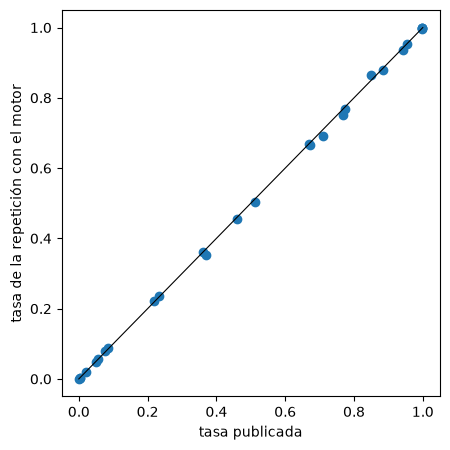

In [6]:
# Repetir celdas de la tabla 4 con muestras iguales y graficarlas contra las publicadas
from riskvalidation.generators.drift import TwoSample
from riskvalidation.harness.rates import agrees_with_published
from riskvalidation.harness.run import metric_above

rules = (metric_above(0.10, "metric>0.1"), metric_above(0.25, "metric>0.25"))
table4 = {(c["row"], c["column"]): c["published"] for c in drift["outputs"]["golden"][0]["cells"]}
columns = (("metric>0.1", "PSI > 0.10"), ("metric>0.25", "PSI > 0.25"), ("p<0.05", "chi-square"))
pairs, agree = [], 0
for size in (100, 200, 400):
    for shift in (0, 0.25, 0.5):
        run = simulate("stability.psi", TwoSample(size, size, shift=shift), n_rep=2000, seed=7, rules=rules)
        for rule, column in columns:
            pub = table4[(f"m {size}, n {size}", f"shift {shift:g} SD, {column}")]
            ok, z = agrees_with_published(run.rates[rule], pub, drift["outputs"]["golden"][0]["runs_published"])
            agree += ok
            pairs.append((pub, run.rates[rule].rate))
print("celdas repetidas:", len(pairs), "| que concuerdan con el documento:", agree)
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.plot([p[0] for p in pairs], [p[1] for p in pairs], "o")
ax.plot([0, 1], [0, 1], color="black", linewidth=0.8)
ax.set_xlabel("tasa publicada")
ax.set_ylabel("tasa de la repetición con el motor")
fig.tight_layout()
plt.show()

Las 27 celdas concuerdan con el artículo, y los puntos caen sobre la diagonal en todo el rango de 0 a 1. La repetición respalda entonces la lectura que el artículo hace de su tabla: la regla de 0,10 tiene un error tipo I muy sobre 5 % con muestras pequeñas, la de 0,25 es demasiado conservadora con muestras sobre 200, y la referencia chi-cuadrado queda cerca del nivel de 5 %. Los hallazgos cualitativos se cumplen para el motor, que es el sentido de repetirlos con una semilla que el artículo nunca usó.

### Demler, Pencina y D'Agostino (2012): DeLong en modelos anidados

Demler et al. (Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23)) muestran que la prueba de DeLong, derivada para modelos con parámetros conocidos, es conservadora cuando compara dos modelos ajustados con los mismos datos y el mayor agrega un predictor sin efecto. Su simulación, con datos tipo Framingham y 1.000 repeticiones, encontró (traducido del inglés): «el nivel de significancia de la prueba F es cercano al nivel nominal de 0,05, mientras que es 0,001 para la prueba de DeLong».


### Paso 5: DeLong en modelos anidados

El archivo guarda la única celda publicada, 0,001, y el diseño del estudio: un par de modelos discriminantes lineales anidados sobre datos del tipo Framingham, 1.000 repeticiones. La celda siguiente lo repite con `NestedLda` y `simulate`, contrasta la tasa con la publicada y corre la misma prueba de DeLong sobre un par de puntajes no anidados en una muestra independiente, donde el artículo no encuentra problema. Un gráfico de barras pone las tres tasas junto al 5 % nominal.

tasa publicada (Demler et al.): 0.001 | anidada, motor: 0.002
z: 0.58 | concuerda: True | no anidada, motor: 0.0525


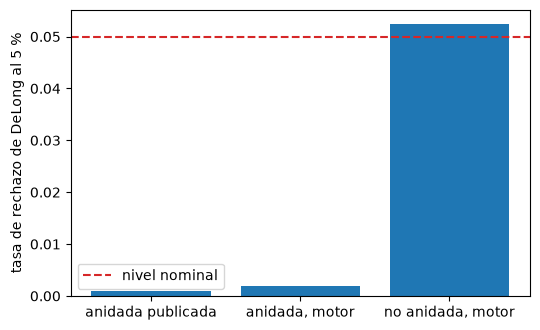

In [7]:
# Repetir la comparación DeLong anidada y compararla con la tasa publicada y con una comparación no anidada
from riskvalidation.generators.framingham import NestedLda
from riskvalidation.generators.scores import BinormalScores

cell = leakage["outputs"]["golden"][0]["cells"][0]
nested = rows["leakage"]["disc.delong@nested"]
nested_gen = NestedLda(**leakage["outputs"]["generators"][nested["generator"]]["config"])
run = simulate("disc.delong", nested_gen, n_rep=nested["n_rep"], seed=nested["seed"])
ok, z = agrees_with_published(run.rates["p<0.05"], cell["published"], leakage["outputs"]["golden"][0]["runs_published"])
other = rows["leakage"]["disc.delong@non-nested"]
pair = BinormalScores(**leakage["outputs"]["generators"][other["generator"]]["config"])
rate_other = simulate("disc.delong", pair, n_rep=other["n_rep"], seed=other["seed"]).rates["p<0.05"]
print("tasa publicada (Demler et al.):", cell["published"], "| anidada, motor:", run.rates["p<0.05"].rate)
print("z:", round(z, 2), "| concuerda:", ok, "| no anidada, motor:", round(rate_other.rate, 4))
fig, ax = plt.subplots(figsize=(5.5, 3.4))
labels = ["anidada publicada", "anidada, motor", "no anidada, motor"]
ax.bar(labels, [cell["published"], run.rates["p<0.05"].rate, rate_other.rate])
ax.axhline(0.05, color="tab:red", linestyle="--", label="nivel nominal")
ax.set_ylabel("tasa de rechazo de DeLong al 5 %")
ax.legend()
fig.tight_layout()
plt.show()

El motor rechaza 0,002 de las comparaciones anidadas frente a 0,001 publicado, una diferencia estandarizada de 0,58, así que la celda concuerda, y la prueba es tan conservadora como dice el artículo: rechaza una comparación correcta una vez de cada quinientas en vez de una de cada veinte. Con un par no anidado la misma prueba rechaza 0,0525, en su nivel. El defecto pertenece al uso de la prueba en modelos anidados ajustados sobre la misma muestra, y un validador que aplica DeLong a un campeón y un retador que comparten predictores pierde casi toda su potencia sin que se le avise.

### Las pruebas del BCE y las herramientas de validación

Las instrucciones del BCE para reportar resultados de validación (2019) definen los estadísticos y los valores p de las pruebas que implementa el motor (la prueba de Jeffreys, el AUC frente al AUC inicial, las pruebas de migración, la prueba de concentración). La investigación del producto (dossier 06, sección A.3) verificó por búsqueda de texto completo que el documento fija estadísticos y valores p y no fija umbrales de aprobación o rechazo, que son responsabilidad de la institución.

Las herramientas que la investigación revisó el 2026-10-04 (dossier 06, sección D, mediante las interfaces de GitHub y PyPI) ofrecen, entre otras:

| Herramienta | Qué lista su documentación | Licencia |
|---|---|---|
| PiML-Toolbox | pruebas de resultado: exactitud, explicabilidad, equidad, puntos débiles, sobreajuste, confiabilidad, robustez, resiliencia; reemplazada por MoDeVa | Apache-2.0 (MoDeVa propietaria) |
| ValidMind | pruebas de validación de datos y de modelo, incluidos PSI, KS, Gini y curvas de calibración, y deriva | AGPL-3.0 o comercial |
| BBVA mercury-robust y mercury-monitoring | pruebas de deriva, filtración de etiquetas, esquema y cohortes | Apache-2.0 |
| ING popmon | deriva: KS, chi-cuadrado, Jensen-Shannon, PSI; semáforos sobre desviaciones de 4 y 7 desviaciones estándar | MIT |
| Evidently | deriva: KS, chi-cuadrado, prueba z, Wasserstein, Jensen-Shannon, PSI, KL; calidad de datos; calidad de modelo | Apache-2.0 |
| NannyML | estimación del desempeño sin etiquetas, deriva univariada y multivariada | Apache-2.0 |
| deepchecks | suites de integridad de datos, validación entrenamiento-prueba y evaluación de modelos | AGPL-3.0 |
| alibi-detect | deriva: KS, MMD, LSDD, chi-cuadrado, basada en clasificador; valores atípicos | BSL 1.1 |

El dossier registra (líneas 1117 a 1121) que ninguna herramienta encontrada implementa exactamente como se especifica las pruebas del BCE de Jeffreys, MWB, z de migración, HHI-CV ni gAUC. Sus catálogos listan pruebas, umbrales y semáforos; el dossier no registró tamaño ni potencia medidos para ellos en los README y la documentación que leyó. Eso es una afirmación sobre lo que encontró la revisión, y NO VERIFICADA más allá de ella: la revisión no ejecutó las herramientas ni leyó su código.

## Resultados

**Respuesta:** El motor reproduce los estudios publicados que se le pidió repetir: los valores críticos del documento de trabajo salen como 19, 35, 49, 63 y 77 incumplimientos, las 27 celdas repetidas del estudio del PSI concuerdan, y la tasa de DeLong anidado es 0,002 frente a 0,001 publicado. Sus veredictos se reparten. El de la prueba binomial se cumple de forma exacta, con un tamaño verdadero de 0,1113 con una correlación de activos de 5 % frente a un 1 % nominal. El de la prueba normal se cumple solo con años dependientes: sus tasas publicadas con años independientes están todas sobre 5 %, entre 0,059 y 0,081. La conclusión de que no existe una prueba potente se cumple con una salvedad: la prueba corregida tiene una potencia de 0,561 en $k = 3$ y la sin corregir, potente, tiene un tamaño de 0,178.

- **Las herramientas documentan pruebas, no tasas de error.** El relevamiento de herramientas halló catálogos de pruebas, umbrales y semáforos, y ninguna medición de tamaño o potencia; es una afirmación sobre la documentación leída, NO VERIFICADA más allá de ella.
- **La literatura midió pocas pruebas.** Tres estudios cubren dos pruebas de calibración, las reglas del PSI y un diseño de DeLong, cada uno con sus propios supuestos.
- **Una repetición con semilla nueva es evidencia.** No depende de los conteos del archivo: las 27 celdas del PSI y la celda de DeLong anidado se sortearon aquí.

Medir cada prueba con un único protocolo es la afirmación del cuaderno siguiente.

## Resumen

- Tres estudios publicados midieron el tamaño o la potencia de pruebas de validación, cada uno sobre un diseño: el documento de trabajo 14 de BCBS, Yurdakul y Naranjo, y Demler et al.
- El motor reproduce sus números: los valores críticos 19, 35, 49, 63 y 77, 27 de 27 celdas del PSI repetidas, y la celda de DeLong anidado.
- El veredicto sobre la prueba binomial se cumple de forma exacta; el de la prueba normal solo cuando los años son dependientes; el de la potencia, con una salvedad.
- La prueba de DeLong es conservadora en modelos anidados y está en su nivel en los no anidados.
- Las herramientas relevadas documentan pruebas, umbrales y semáforos, y ninguna tasa de error medida.

**Qué probar después.** Repite el paso 3 con una correlación de activos de 20 % y compara las potencias; luego lee el cuaderno 08.

## Referencias

- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): los veredictos sobre las pruebas de calibración (páginas 41 a 42), los ejemplos del apéndice sobre la prueba binomial, y la simulación de las pruebas normal y de semáforo (páginas 61 a 67). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Demler, O. V., Pencina, M. J. y D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Los dossiers de investigación del producto (registros de CAOS_MANAGE, `wip/contraste/`): 06 (gestión del riesgo de modelo y validación, secciones A, C y D) y 12 (tamaño, potencia y generadores, secciones 1 a 6), leídos el 2026-10-04 y el 2026-10-05; y `docs/design/features/c22-validator/requirements.md` de este repositorio.